# Assignment 3: Combined binary student-dropout analysis

Run from **`notebooks/assignment3/`** after installing the repository's `requirements.txt`.
Input: `../../data/graduation_dataset.csv`. Numeric results: `../../results/assignment3/combined/`.
Figures: `../../figures/assignment3/combined/`. Restart the kernel and run all cells in order.
The original CSV and previous assignment notebooks are preserved. This notebook is self-contained.

This new experiment combines ideas, not previously reported scores, from four reviewed versions:

| Version | Contribution retained | Correction made in this experiment |
|---|---|---|
| Elling, `3cb1c64` | Fold-contained pipelines, binary population, operational evaluation, cross-course transfer | Required ensembles use different base algorithm families |
| Johan, `ebc4071` | Linear/RBF SVM comparison and PCA/LDA experiments | All transformations fitted inside CV; no concatenation of all PCA axes with LDA |
| Mats, `1433aba` | Multiple feature counts, rare-category experiment, regularization and resource trade-offs | Rare grouping inside folds; no test-guided model changes |
| Fredrik, `36d8a11` | Explicit PyTorch training, log ablation, ranking metrics and reproducibility exports | Binary target, wider feature study and five-fold development evaluation |

The assignment's ten numbered requirements are followed below. Search budgets, metrics, feature
formulas and the 20% contact capacity are declared experimental choices, not additional brief requirements.


## 1. Develop a problem statement (real world and machine learning)

### a. Connect the learning task to a real-world scenario

**Research question:** How can machine learning use student background information and first-year
academic results to distinguish recorded dropout from graduation, and assess the potential to help
academic advisors prioritize student support at the end of the first academic year?

**Real-world decision.** Advisors have limited appointments and need an ordered worklist for offering
voluntary academic/support conversations. We assume capacity to contact 20% of students. Missing a
student who needs help and contacting a student with another outcome have different practical costs;
we report precision, recall and workload rather than inventing monetary costs. A flagged outcome
does not itself show whether a student needs help or would benefit from it.

**Learning problem.** Binary classification: `Dropout = 1`, `Graduate = 0`. The 794 `Enrolled`
records have unresolved eventual outcomes, so they are excluded from supervised fitting and evaluation,
not relabelled as confirmed non-dropouts. This changes the population: the evaluation concerns resolved
outcomes and does not validate accuracy on all active students. Optional scores for unresolved students
are exported only after development; there is no known final label with which to assess those scores.

**Prediction time and limits.** Both semesters are used, so the proposed decision time is the end of
year one. The source describes status at normal programme duration, but the CSV supplies no dropout
date, timestamped administrative history or cohort identifier. Some dropouts may already have left
during year one. Thus this is retrospective feasibility analysis, not demonstrated warning before
dropout. We exclude debtor/payment-status fields with unverified availability dates; that does not
establish timing for every other field. Future validation needs students still active at the decision
date, information available then, subsequent outcomes and evidence that actual support helps.

**Selection objective.** Average precision (AP) is primary because dropout is the positive class and
we need a useful ranking. AP summarizes precision-recall performance, not accuracy. Precision/recall
at the predeclared 20% capacity translate the ranking to appointments; the AP leader need not lead
at exactly that capacity. F2 thresholds provide a separate recall-oriented alert analysis and may
produce more alerts than appointments. Neither policy is optimized on test labels.

Sources: [UCI dataset description](https://archive.ics.uci.edu/dataset/697/predict+students+dropout+and+academic+success)
and [Realinho et al. (2022)](https://doi.org/10.3390/data7110146). The local 35-column file is used
as supplied; we do not substitute the current UCI schema or assume its category-code meanings.


## 2. Implement preprocessing and justify the preprocessing steps

### Data integrity, population and a held-out test partition

Original numerical/categorical codes are audited. Plausible extreme ages and count values are retained;
a zero grade is not automatically changed to missing. Missing targets are not guessed. This file is
expected to contain no missing predictors; explicit checks fail if that changes rather than silently
introducing a new imputation policy. A single header alias is normalized without changing any values.

The resolved population is split approximately 80/20, stratified, grouped and seeded. After excluding
the two administrative fields, indistinguishable predictor profiles are kept in the same partition
even if their labels differ. This does not assert that they are the same person and does not delete
either outcome. All development uses five fixed, profile-grouped folds
within the 80%. The held-out test predictors/outcomes are not scored until section 10. Selected CV
results reuse development data across experiments and are not unbiased nested-CV estimates.


In [1]:
from pathlib import Path
from time import perf_counter
from copy import deepcopy
import hashlib
import inspect
import json
import platform
import random
import sys
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import torch
from torch import nn
from IPython.display import display, Markdown
from sklearn.base import BaseEstimator, ClassifierMixin, TransformerMixin, clone
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import AdaBoostClassifier, BaggingClassifier
from sklearn.feature_selection import SelectKBest, VarianceThreshold, f_classif
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, average_precision_score, balanced_accuracy_score,
    brier_score_loss, classification_report, confusion_matrix, ConfusionMatrixDisplay,
    f1_score, fbeta_score, log_loss, precision_recall_curve, precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import (GridSearchCV, StratifiedGroupKFold, cross_val_predict,
    cross_validate, train_test_split)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from threadpoolctl import threadpool_limits

SEED = 42
CAPACITY = .20
DATA = Path('../../data/graduation_dataset.csv')
RESULTS = Path('../../results/assignment3/combined')
FIGURES = Path('../../figures/assignment3/combined')
assert DATA.is_file(), 'Run from notebooks/assignment3/ with the original CSV in data/.'
RESULTS.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)
np.random.seed(SEED)
random.seed(SEED)
torch.manual_seed(SEED)
torch.use_deterministic_algorithms(True)
torch.set_num_threads(2)
thread_limits = threadpool_limits(limits=2)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})

raw = pd.read_csv(DATA, encoding='utf-8-sig')
if 'Nacionality' in raw.columns:
    assert 'Nationality' not in raw.columns, 'Ambiguous duplicate nationality fields.'
    raw = raw.rename(columns={'Nacionality': 'Nationality'})
assert raw.columns.is_unique and raw.shape[1] == 35
assert set(raw.Target) == {'Dropout', 'Graduate', 'Enrolled'}
assert not raw.isna().any().any(), 'Missing values require a justified training-fitted imputation policy.'
assert not raw.duplicated().any(), 'Investigate duplicates and use grouped splits if needed.'
assert np.isfinite(raw.drop(columns='Target').to_numpy(dtype=float)).all()
display(pd.Series({'students': len(raw), 'columns': raw.shape[1],
    'missing_cells': int(raw.isna().sum().sum()), 'duplicates': int(raw.duplicated().sum())}).to_frame('audit'))
display(raw.Target.value_counts().to_frame('students'))

EXCLUDED = ['Debtor', 'Tuition fees up to date']
resolved = raw.loc[raw.Target.isin(['Dropout', 'Graduate'])].copy()
unresolved = raw.loc[raw.Target == 'Enrolled'].copy()
X = resolved.drop(columns=['Target'] + EXCLUDED)
y = resolved.Target.map({'Graduate': 0, 'Dropout': 1}).astype(int)
profile_groups = pd.util.hash_pandas_object(X, index=False).to_numpy()
display(pd.Series({'repeated_retained_predictor_rows': int(X.duplicated().sum()),
    'distinct_retained_profiles': int(pd.Series(profile_groups).nunique())}).to_frame('profile_audit'))
NOMINAL = ['Marital status', 'Application mode', 'Course', 'Previous qualification',
    'Nationality', "Mother's qualification", "Father's qualification", "Mother's occupation", "Father's occupation"]
BINARY = ['Daytime/evening attendance', 'Displaced', 'Educational special needs',
          'Gender', 'Scholarship holder', 'International']
NUMERIC = [c for c in X.columns if c not in NOMINAL + BINARY]
COUNTS = [c for c in NUMERIC if c.startswith('Curricular units') and not c.endswith('(grade)')]
GRADES = [c for c in NUMERIC if c.endswith('(grade)')]
assert (X[COUNTS] >= 0).all().all()
assert ((X[GRADES] >= 0) & (X[GRADES] <= 20)).all().all()
assert all(set(X[c]).issubset({0, 1}) for c in BINARY)
def profile_holdout(frame, labels, n_splits):
    groups = pd.util.hash_pandas_object(frame, index=False).to_numpy()
    splitter = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=SEED)
    train, validation = next(splitter.split(frame, labels, groups))
    assert set(groups[train]).isdisjoint(groups[validation])
    return train, validation


dev_indices, test_indices = profile_holdout(X, y, n_splits=5)
X_dev, X_test = X.iloc[dev_indices], X.iloc[test_indices]
y_dev, y_test = y.iloc[dev_indices], y.iloc[test_indices]
CV = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
dev_groups = pd.util.hash_pandas_object(X_dev, index=False).to_numpy()
FOLDS = list(CV.split(X_dev, y_dev, dev_groups))
assert all(set(dev_groups[a]).isdisjoint(dev_groups[b]) for a, b in FOLDS)
assert set(X_dev.index).isdisjoint(X_test.index)
assert X_dev.index.equals(y_dev.index) and X_test.index.equals(y_test.index)
split_table = pd.DataFrame({'students': [len(X_dev), len(X_test), len(unresolved)],
    'role': ['development and five-fold CV', 'held-out final evaluation', 'unknown eventual outcome; not scored for accuracy']},
    index=['development', 'test', 'unresolved'])
display(split_table)
membership = pd.concat([pd.DataFrame({'row_id': frame.index, 'partition': name})
    for name, frame in [('development', X_dev), ('test', X_test), ('unresolved', unresolved)]])
assert membership.row_id.nunique() == len(raw)
membership.to_csv(RESULTS / 'partition_membership.csv', index=False)
environment = {'python': sys.version, 'platform': platform.platform(), 'numpy': np.__version__,
    'pandas': pd.__version__, 'sklearn': sklearn.__version__, 'torch': torch.__version__,
    'device': 'cpu', 'threads': 2, 'seed': SEED, 'data_sha256': hashlib.sha256(DATA.read_bytes()).hexdigest()}
(RESULTS / 'environment.json').write_text(json.dumps(environment, indent=2), encoding='utf-8')
display(pd.Series(environment).to_frame('environment'))


,audit
students,4424
columns,35
missing_cells,0
duplicates,0


,students
Target,
Graduate,2209
Dropout,1421
Enrolled,794


,profile_audit
repeated_retained_predictor_rows,1
distinct_retained_profiles,3629


,students,role
development,2904,development and five-fold CV
test,726,held-out final evaluation
unresolved,794,unknown eventual outcome; not scored for accuracy


,environment
python,"3.13.7 (tags/v3.13.7:bcee1c3, Aug 14 2025, 14:..."
platform,Windows-11-10.0.26200-SP0
numpy,2.5.4
pandas,3.0.5
sklearn,1.9.0
torch,2.14.1+cpu
device,cpu
threads,2
seed,42
data_sha256,c1622e34fd2cd39c93b0052da9367ad5ddaacc44a25807...


### Reusable transformations and development ablations

One-hot encoding avoids numeric distances between nominal codes. Original and engineered binary flags
remain 0/1. Numeric values are standardized using training means/standard deviations; application
order is explicitly treated as an ordered numeric predictor. Trees do not need scaling, but the common
representation simplifies comparisons. Unknown categories are handled without refitting on validation.

Two optional changes are tested with a fixed logistic-regression probe and identical folds:
`log1p` of nonnegative count columns whose **fold-training** skewness exceeds 2, and grouping
categories below 1% **within the fitted encoder**. No global frequency table is used. These are small
development ablations, not a demonstration of the optimal preprocessing for every algorithm.
The winning configuration is fixed for subsequent experiments; exact AP ties favour fewer changes.


In [2]:
DERIVED_NUMERIC = ['approval_rate_s1', 'evaluation_intensity_s1', 'approval_rate_s2',
    'evaluation_intensity_s2', 'approved_total', 'approval_rate_year', 'approval_trend', 'grade_trend']
DERIVED_BINARY = ['zero_enrolment_s1', 'zero_enrolment_s2', 'zero_approved_any']
DERIVED = DERIVED_NUMERIC + DERIVED_BINARY


class AcademicFeatures(TransformerMixin, BaseEstimator):
    def __init__(self, enabled=True):
        self.enabled = enabled

    def fit(self, X, y=None):
        self.feature_names_in_ = np.asarray(X.columns, dtype=object)
        self.n_features_in_ = X.shape[1]
        self.output_features_ = np.asarray(self.transform(X).columns, dtype=object)
        return self

    def transform(self, X):
        out = X.copy()
        if not self.enabled:
            return out
        def ratio(num, den):
            return np.divide(np.asarray(num, dtype=float), np.asarray(den, dtype=float),
                out=np.zeros(len(out)), where=np.asarray(den) != 0)
        for s, suffix in [(1, '1st'), (2, '2nd')]:
            enrolled = out[f'Curricular units {suffix} sem (enrolled)']
            out[f'approval_rate_s{s}'] = ratio(out[f'Curricular units {suffix} sem (approved)'], enrolled)
            out[f'evaluation_intensity_s{s}'] = ratio(out[f'Curricular units {suffix} sem (evaluations)'], enrolled)
            out[f'zero_enrolment_s{s}'] = enrolled.eq(0).astype(int)
        out['approved_total'] = out['Curricular units 1st sem (approved)'] + out['Curricular units 2nd sem (approved)']
        total_enrolled = out['Curricular units 1st sem (enrolled)'] + out['Curricular units 2nd sem (enrolled)']
        out['approval_rate_year'] = ratio(out['approved_total'], total_enrolled)
        out['approval_trend'] = out.approval_rate_s2 - out.approval_rate_s1
        out['grade_trend'] = out['Curricular units 2nd sem (grade)'] - out['Curricular units 1st sem (grade)']
        out['zero_approved_any'] = ((out['Curricular units 1st sem (approved)'] == 0) |
                                    (out['Curricular units 2nd sem (approved)'] == 0)).astype(int)
        return out

    def get_feature_names_out(self, input_features=None):
        return self.output_features_.copy()


class AdaptiveLog(TransformerMixin, BaseEstimator):
    def __init__(self, enabled=False, indices=()):
        self.enabled = enabled
        self.indices = indices

    def fit(self, X, y=None):
        arr = np.asarray(X, dtype=float)
        self.n_features_in_ = arr.shape[1]
        skew = pd.DataFrame(arr).skew().to_numpy()
        self.selected_ = np.array([i for i in self.indices if self.enabled and skew[i] > 2
                                   and np.min(arr[:, i]) >= 0], dtype=int)
        return self

    def transform(self, X):
        arr = np.array(X, dtype=float, copy=True)
        if self.selected_.size:
            assert (arr[:, self.selected_] >= 0).all()
            arr[:, self.selected_] = np.log1p(arr[:, self.selected_])
        return arr

    def get_feature_names_out(self, input_features=None):
        return np.asarray(input_features, dtype=object)


def preprocessor(engineered=True, use_log=False, rare=False):
    numeric = NUMERIC + (DERIVED_NUMERIC if engineered else [])
    binary = BINARY + (DERIVED_BINARY if engineered else [])
    indices = tuple(i for i, col in enumerate(numeric) if col in COUNTS)
    encoder = OneHotEncoder(sparse_output=False, min_frequency=.01 if rare else None,
        handle_unknown='infrequent_if_exist' if rare else 'ignore')
    return ColumnTransformer([
        ('numeric', Pipeline([('log', AdaptiveLog(use_log, indices)), ('scale', StandardScaler())]), numeric),
        ('binary', 'passthrough', binary), ('nominal', encoder, NOMINAL)])


def f_scores(X, y):
    with np.errstate(divide='ignore', invalid='ignore'):
        scores, _ = f_classif(X, y)
    return np.nan_to_num(scores, nan=0., posinf=1e12, neginf=0.)


def model_pipeline(model, engineered=True, use_log=False, rare=False, reduction='passthrough'):
    return Pipeline([('features', AcademicFeatures(engineered)),
        ('preprocessing', preprocessor(engineered, use_log, rare)),
        ('constant', VarianceThreshold()), ('reduction', reduction), ('model', model)])


def risk_scores(estimator, frame):
    assert np.array_equal(estimator.classes_, [0, 1])
    if hasattr(estimator, 'predict_proba'):
        return estimator.predict_proba(frame)[:, 1]
    return estimator.decision_function(frame)


def capacity_metrics(truth, scores, capacity=CAPACITY):
    truth, scores = np.asarray(truth), np.asarray(scores)
    assert np.isfinite(scores).all() and len(scores) == len(truth)
    k = max(1, int(np.ceil(capacity * len(truth))))
    order = np.argsort(-scores, kind='stable')[:k]
    found = int(truth[order].sum())
    return {'contacts': k, 'dropouts_reached': found, 'other_contacts': k - found,
        'precision_at_capacity': found / k, 'recall_at_capacity': found / truth.sum()}


def recall_capacity_scorer(estimator, frame, labels):
    return capacity_metrics(labels, risk_scores(estimator, frame))['recall_at_capacity']


def save_figure(fig, name):
    fig.tight_layout()
    fig.savefig(FIGURES / name, dpi=160, bbox_inches='tight')
    plt.show()


probe = LogisticRegression(C=1., max_iter=1500, class_weight='balanced', random_state=SEED)
prep_rows = []
for use_log in [False, True]:
    for rare in [False, True]:
        pipe = model_pipeline(clone(probe), engineered=False, use_log=use_log, rare=rare)
        scores = cross_validate(pipe, X_dev, y_dev, cv=FOLDS, scoring='average_precision', n_jobs=1)
        prep_rows.append({'log': use_log, 'rare_pooling': rare, 'CV_AP': scores['test_score'].mean(),
            'fold_SD': scores['test_score'].std(ddof=1), 'changes': int(use_log) + int(rare)})
prep_results = pd.DataFrame(prep_rows).sort_values(['CV_AP', 'changes', 'log', 'rare_pooling'],
                                                ascending=[False, True, True, True])
USE_LOG = bool(prep_results.iloc[0]['log'])
USE_RARE = bool(prep_results.iloc[0]['rare_pooling'])
display(prep_results.round(4))
display(Markdown(f'**Development choice:** log={USE_LOG}, rare-category pooling={USE_RARE}. '
    'All four candidates used the same five folds. These selected scores remain development estimates.'))
prep_results.to_csv(RESULTS / 'preprocessing_ablation.csv', index=False)


,log,rare_pooling,CV_AP,fold_SD,changes
1,False,True,0.9380,0.0185,1
0,False,False,0.9376,0.0184,0
3,True,True,0.9360,0.0170,2
2,True,False,0.9355,0.0169,1


**Development choice:** log=False, rare-category pooling=True. All four candidates used the same five folds. These selected scores remain development estimates.

## 3. Extract features and justify the methods used

The combined eleven features represent progress relative to course load and change between semesters.
`approval_rate_s1/s2` are approved/enrolled; `evaluation_intensity_s1/s2` are evaluations/enrolled.
`approved_total` sums passed units, and `approval_rate_year` divides that sum by total enrolled units
(a load-weighted annual rate, not an unweighted mean of semester rates). `approval_trend` and
`grade_trend` are semester 2 minus semester 1. `zero_enrolment_s1/s2` identify undefined ratios;
`zero_approved_any` indicates no approved units in at least one semester.

Zero-denominator ratios are represented by zero plus the explicit indicators. Zero grades remain
ambiguous source observations. The features are per-student formulas using no labels; correlated
or redundant derived columns are possible and will be assessed in point 4. Financial-risk combinations
are omitted because they would reintroduce excluded administrative fields.

The original data sometimes report more units without evaluation than enrolled units. We audit this
on development data and omit the proposed no-evaluation *rate* until its meaning is clarified; raw
counts remain available. We do not silently cap values or treat a ratio above one as a valid proportion.
The same fixed tree is evaluated with and without engineering, with all nonconstant features, inside CV.


In [3]:
ratio_flags = []
for suffix in ['1st', '2nd']:
    enrolled = X_dev[f'Curricular units {suffix} sem (enrolled)']
    without = X_dev[f'Curricular units {suffix} sem (without evaluations)']
    ratio_flags.append({'semester': suffix, 'without_evaluation_exceeds_enrolled': int((without > enrolled).sum())})
display(pd.DataFrame(ratio_flags))
feature_rows = []
for enabled in [False, True]:
    pipe = model_pipeline(DecisionTreeClassifier(max_depth=5, min_samples_leaf=10, random_state=SEED),
                          engineered=enabled, use_log=USE_LOG, rare=USE_RARE)
    scores = cross_validate(pipe, X_dev, y_dev, cv=FOLDS, scoring='average_precision', n_jobs=1)
    feature_rows.append({'engineered': enabled, 'CV_AP': scores['test_score'].mean(),
                         'fold_SD': scores['test_score'].std(ddof=1)})
feature_results = pd.DataFrame(feature_rows)
display(feature_results.round(4))
delta = feature_results.iloc[1].CV_AP - feature_results.iloc[0].CV_AP
display(Markdown(f'Adding the eleven features changes tree CV AP by **{delta:+.4f}**. '
    'This fixed-model ablation is not proof of a gain for every classifier. The main searches '
    'retain engineered columns and allow supervised selection to remove weak columns.'))
display(AcademicFeatures().fit_transform(X_dev)[DERIVED].describe().round(3))
feature_results.to_csv(RESULTS / 'feature_engineering_ablation.csv', index=False)


,semester,without_evaluation_exceeds_enrolled
0,1st,0
1,2nd,3


,engineered,CV_AP,fold_SD
0,False,0.8991,0.0230
1,True,0.9088,0.0214


Adding the eleven features changes tree CV AP by **+0.0097**. This fixed-model ablation is not proof of a gain for every classifier. The main searches retain engineered columns and allow supervised selection to remove weak columns.

,approval_rate_s1,evaluation_intensity_s1,approval_rate_s2,evaluation_intensity_s2,approved_total,approval_rate_year,approval_trend,grade_trend,zero_enrolment_s1,zero_enrolment_s2,zero_approved_any
count,2904.000,2904.000,2904.000,2904.000,2904.000,2904.000,2904.000,2904.000,2904.000,2904.000,2904.000
mean,0.700,1.235,0.663,1.196,9.297,0.681,-0.037,-0.545,0.044,0.044,0.229
std,0.379,0.562,0.402,0.568,6.255,0.381,0.175,2.953,0.205,0.205,0.420
min,0.000,0.000,0.000,0.000,0.000,0.000,-1.000,-16.000,0.000,0.000,0.000
25%,0.500,1.000,0.325,1.000,4.000,0.400,0.000,-0.548,0.000,0.000,0.000
50%,0.857,1.167,0.857,1.167,10.000,0.875,0.000,0.000,0.000,0.000,0.000
75%,1.000,1.500,1.000,1.500,12.000,1.000,0.000,0.353,0.000,0.000,0.000
max,1.000,3.333,1.000,3.500,43.000,1.000,1.000,14.500,1.000,1.000,1.000


## 4. Select features or use dimensionality reduction and justify the methods

We compare all nonconstant columns, **explicit ANOVA feature counts**, PCA and LDA. ANOVA retains
named input columns by univariate association; it can miss interactions and select redundant columns.
PCA instead forms mixtures preserving input variance, which need not preserve dropout discrimination.
LDA is supervised: for two classes its projection has at most one axis, potentially too restrictive
for nonlinear patterns. Both mix original variables and are less directly explainable to advisors.
We do not concatenate all PCA components with an LDA score and call that reduction.

Counts 25/50/100/150 are included only if valid in every training fold after encoding/filtering.
PCA candidates are 10 axes, 40 axes, and 95% retained variance; 95% variance is not 95% accuracy.
The same logistic probe provides an initial comparison, not a universal choice of representation.
The three main classifiers subsequently tune their own representation and classifier parameters
together. This avoids selecting PCA parameters using the test set or assuming that hyperparameters
tuned on original features must also be optimal after reduction.


Nonconstant training-fold dimensions: [116, 116, 115, 115, 115]
Valid ANOVA counts: [25, 50, 100]


,representation,CV_AP,fold_SD
3,ANOVA k=100,0.9409,0.0147
0,all,0.9389,0.0185
2,ANOVA k=50,0.9386,0.0187
7,LDA k=1,0.9381,0.0194
1,ANOVA k=25,0.9374,0.0203
6,PCA variance=95%,0.9364,0.0194
5,PCA k=40,0.9358,0.0209
4,PCA k=10,0.9204,0.0168


,feature,F_score
19,numeric__approval_rate_s2,3429.27
22,numeric__approval_rate_year,3161.92
17,numeric__approval_rate_s1,2361.50
11,numeric__Curricular units 2nd sem (approved),2120.24
21,numeric__approved_total,1764.60
12,numeric__Curricular units 2nd sem (grade),1666.58
33,binary__zero_approved_any,1398.49
5,numeric__Curricular units 1st sem (approved),1294.85
6,numeric__Curricular units 1st sem (grade),1034.60
29,binary__Scholarship holder,350.81


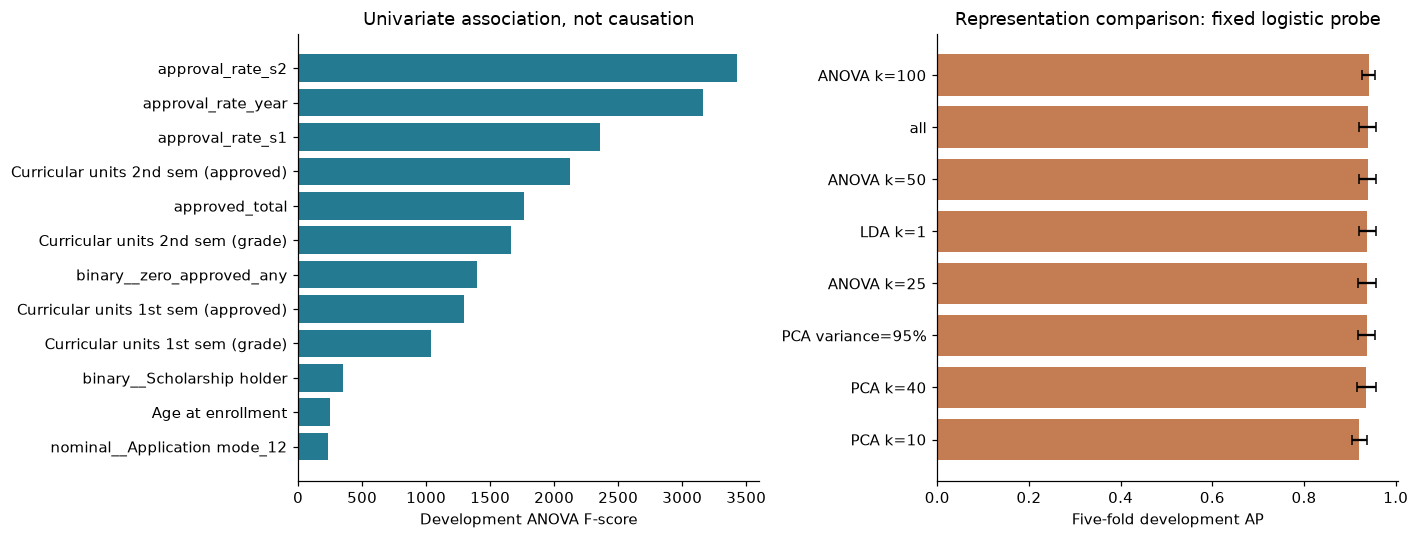

In [4]:
def base_representation(engineered=True):
    return model_pipeline(DummyClassifier(), engineered, USE_LOG, USE_RARE)[:-2]


fold_widths = [base_representation().fit_transform(X_dev.iloc[train], y_dev.iloc[train]).shape[1]
               for train, _ in FOLDS]
min_width = min(fold_widths)
K_VALUES = [k for k in [25, 50, 100, 150] if k <= min_width]
REPRESENTATIONS = [('all', 'passthrough')]
REPRESENTATIONS += [(f'ANOVA k={k}', SelectKBest(f_scores, k=k)) for k in K_VALUES]
REPRESENTATIONS += [(f'PCA k={k}', PCA(n_components=k, svd_solver='full'))
                    for k in [10, 40] if k <= min_width]
REPRESENTATIONS += [('PCA variance=95%', PCA(n_components=.95, svd_solver='full')),
                    ('LDA k=1', LinearDiscriminantAnalysis(n_components=1))]
print('Nonconstant training-fold dimensions:', fold_widths)
print('Valid ANOVA counts:', K_VALUES)
representation_rows = []
for name, reducer in REPRESENTATIONS:
    pipe = model_pipeline(clone(probe), use_log=USE_LOG, rare=USE_RARE, reduction=deepcopy(reducer))
    scores = cross_validate(pipe, X_dev, y_dev, cv=FOLDS, scoring='average_precision', n_jobs=1)
    representation_rows.append({'representation': name, 'CV_AP': scores['test_score'].mean(),
        'fold_SD': scores['test_score'].std(ddof=1)})
representation_results = pd.DataFrame(representation_rows).sort_values('CV_AP', ascending=False)
display(representation_results.round(4))
representation_results.to_csv(RESULTS / 'representation_probe.csv', index=False)

preview = base_representation().fit(X_dev, y_dev)
matrix = preview.transform(X_dev)
names = preview.named_steps['preprocessing'].get_feature_names_out()[preview.named_steps['constant'].get_support()]
ranking = pd.DataFrame({'feature': names, 'F_score': f_scores(matrix, y_dev)}).sort_values('F_score', ascending=False)
ranking.to_csv(RESULTS / 'development_anova_ranking.csv', index=False)
display(ranking.head(15).round(2))
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
top = ranking.head(12).iloc[::-1]
axes[0].barh(top.feature.str.replace('numeric__', '', regex=False), top.F_score, color='#247b91')
axes[0].set(xlabel='Development ANOVA F-score', title='Univariate association, not causation')
plot = representation_results.iloc[::-1]
axes[1].barh(plot.representation, plot.CV_AP, xerr=plot.fold_SD, color='#c47d52', capsize=3)
axes[1].set(xlabel='Five-fold development AP', title='Representation comparison: fixed logistic probe')
save_figure(fig, '01_features_and_representations.png')


## 5. Implement three algorithms and justify the choice

### a. K-nearest neighbours

KNN tests whether students with similar profiles have similar outcomes. Tune k=11/31 and
uniform/distance weights. Stored examples make fitting cheap but prediction can be costly; many
irrelevant encoded columns can distort distances, motivating per-model representation selection.

### d. Decision trees

Trees express nonlinear rules and interactions that can be inspected. Tune depth 4/8 and minimum
leaf size 5/20; balanced class weights are fixed to account for status frequencies. Depth and leaf
constraints limit variance. PCA/LDA may change how well simple axis-aligned splits work; we measure it.

### f. SVM with kernels

Compare linear C=0.1/1 and RBF C=0.5/2 with gamma=`scale`/0.01. C controls error penalties and
gamma the locality of RBF similarity. Balanced class weights and numeric scaling are fixed. Raw
decision margins support ranking without expensive probability fitting; margins are not probabilities.

Each family searches all declared representations using identical development folds. Search sizes
differ and are recorded. AP selects candidates; mean fold recall at the 20% budget breaks exact AP
ties. Every search refits its winner on all development rows. A prior-only dummy establishes a
no-information reference. The test set remains untouched. Selected CV scores can be optimistic
because the same development data has supported earlier choices; they are not nested-CV estimates.


In [5]:
records = {}
searches = {}
search_rows = []
SCORING = {'AP': 'average_precision', 'ROC_AUC': 'roc_auc', 'recall_capacity': recall_capacity_scorer}


def describe_parameters(value):
    if isinstance(value, BaseEstimator):
        return {'class': type(value).__name__, 'parameters': describe_parameters(value.get_params(deep=False))}
    if isinstance(value, dict):
        return {key: describe_parameters(item) for key, item in value.items()}
    if isinstance(value, (tuple, list)):
        return [describe_parameters(item) for item in value]
    if isinstance(value, np.generic):
        return value.item()
    if callable(value):
        return value.__name__
    return value


def refit_index(cv_results):
    ap = np.asarray(cv_results['mean_test_AP'])
    recall = np.asarray(cv_results['mean_test_recall_capacity'])
    return int(np.lexsort((-recall, -ap))[0])


def run_search(name, estimator, grids, family, representations=True):
    if representations:
        candidates = []
        for grid in grids:
            for _, reducer in REPRESENTATIONS:
                candidates.append({**grid, 'reduction': [deepcopy(reducer)]})
        pipeline = model_pipeline(estimator, use_log=USE_LOG, rare=USE_RARE)
    else:
        candidates, pipeline = grids, estimator
    search = GridSearchCV(pipeline, candidates, scoring=SCORING, refit=refit_index,
        cv=FOLDS, n_jobs=1, error_score='raise', return_train_score=False)
    start = perf_counter()
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter('always')
        search.fit(X_dev, y_dev)
    elapsed = perf_counter() - start
    i = search.best_index_
    row = {'model': name, 'family': family, 'CV_AP': search.cv_results_['mean_test_AP'][i],
        'fold_SD': search.cv_results_['std_test_AP'][i],
        'CV_ROC_AUC': search.cv_results_['mean_test_ROC_AUC'][i],
        'CV_recall_capacity': search.cv_results_['mean_test_recall_capacity'][i],
        'search_seconds': elapsed, 'refit_seconds': search.refit_time_,
        'candidates': len(search.cv_results_['params']), 'warnings': len(caught)}
    records[name] = {**row, 'model': search.best_estimator_, 'parameters': search.best_params_}
    assert hasattr(records[name]['model'], 'predict'), 'Store the fitted estimator, not its display name.'
    searches[name] = search
    search_rows.append(row)
    trials = pd.DataFrame(search.cv_results_)
    trials['params'] = trials['params'].map(lambda params: json.dumps(describe_parameters(params)))
    trials.to_csv(RESULTS / f'search_{name.replace(" ", "_")}.csv', index=False)
    print(f'{name}: CV AP={row["CV_AP"]:.4f}; {row["candidates"]} candidates; {elapsed:.1f}s', flush=True)
    if caught:
        for message in sorted({str(w.message) for w in caught}):
            print('  Warning:', message[:250], flush=True)
    return search


run_search('Prior baseline', model_pipeline(DummyClassifier(strategy='prior'), use_log=USE_LOG, rare=USE_RARE),
           [{}], 'reference', representations=False)
run_search('KNN', KNeighborsClassifier(n_jobs=1),
    [{'model__n_neighbors': [11, 31], 'model__weights': ['uniform', 'distance']}], 'basic')
run_search('Decision tree', DecisionTreeClassifier(class_weight='balanced', random_state=SEED),
    [{'model__max_depth': [4, 8], 'model__min_samples_leaf': [5, 20]}], 'basic')
run_search('SVM', SVC(class_weight='balanced', random_state=SEED, cache_size=512),
    [{'model__kernel': ['linear'], 'model__C': [.1, 1.]},
     {'model__kernel': ['rbf'], 'model__C': [.5, 2.], 'model__gamma': ['scale', .01]}], 'basic')
display(pd.DataFrame([{'model': n, 'parameters': json.dumps(describe_parameters(records[n]['parameters']))}
                     for n in ['KNN', 'Decision tree', 'SVM']]))


Prior baseline: CV AP=0.3915; 1 candidates; 0.3s


KNN: CV AP=0.9279; 32 candidates; 10.2s


Decision tree: CV AP=0.9226; 32 candidates; 9.5s


SVM: CV AP=0.9417; 48 candidates; 41.8s


,model,parameters
0,KNN,"{""model__n_neighbors"": 31, ""model__weights"": ""..."
1,Decision tree,"{""model__max_depth"": 8, ""model__min_samples_le..."
2,SVM,"{""model__C"": 2.0, ""model__gamma"": 0.01, ""model..."


## 6. Compare the three algorithms and explain results in relation to the problem

Report development CV means and fold variation, not test results. Fold SD is not a confidence
interval, and comparisons after tuning are not independent hypothesis tests. A training out-of-fold
(OOF) prediction for each student supports a separate F2 alert threshold: F2 weights recall more
than precision. That preference is an assumption, not a measured cost model. The same data supported
parameter selection, so these OOF summaries are development estimates rather than unbiased estimates.

The capacity policy always selects the top 20%; F2 alerts may exceed that budget. Stable ordering
breaks tied scores reproducibly but does not create risk distinctions between tied students. SVM
OOF margins can differ in scale across folds/refitting, so its threshold is less transferable than
its rank order. All thresholds are fixed before final evaluation; calibration is assessed separately.


,family,CV_AP,fold_SD,CV_ROC_AUC,CV_recall_capacity,search_seconds,refit_seconds,candidates,warnings
model,,,,,,,,,
SVM,basic,0.9417,0.0105,0.9461,0.5128,41.8102,0.1680,48,0
KNN,basic,0.9279,0.0145,0.9352,0.5119,10.2368,0.0214,32,0
Decision tree,basic,0.9226,0.0117,0.9297,0.5092,9.4583,0.0294,32,0
Prior baseline,reference,0.3915,0.0006,0.5000,0.1785,0.2777,0.0264,1,0


,OOF_AP,F2_threshold,OOF_F2,contacts,dropouts_reached,other_contacts,precision_at_capacity,recall_at_capacity
model,,,,,,,,
Prior baseline,0.3912,0.3913,0.7629,581,227,354,0.3907,0.1996
KNN,0.9276,0.2258,0.8575,581,581,0,1.0000,0.5110
Decision tree,0.9264,0.1969,0.8645,581,577,4,0.9931,0.5075
SVM,0.9414,-0.5489,0.8826,581,581,0,1.0000,0.5110


**Measured development result:** SVM leads the three basic families by CV AP (0.9417). The representation and parameter table shows which input space supports that result; it does not establish universal superiority.

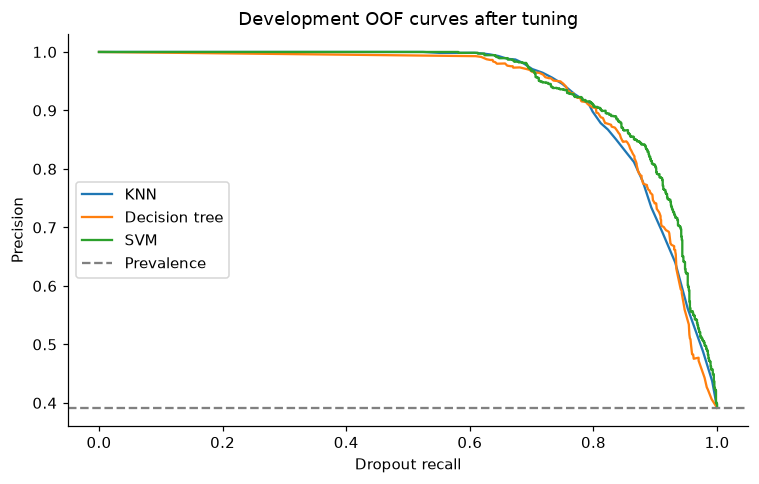

,model,input_columns,model_inputs,representation
0,KNN,114,25,ANOVA selection
1,Decision tree,114,50,ANOVA selection
2,SVM,114,100,ANOVA selection


In [6]:
def development_table():
    return pd.DataFrame(search_rows).set_index('model').sort_values(
        ['CV_AP', 'CV_recall_capacity'], ascending=False)


def register_oof(name):
    fitted = records[name]['model']
    method = 'predict_proba' if hasattr(fitted, 'predict_proba') else 'decision_function'
    output = cross_val_predict(clone(fitted), X_dev, y_dev, cv=FOLDS, method=method, n_jobs=1)
    score = output[:, 1] if method == 'predict_proba' else output
    p, r, thresholds = precision_recall_curve(y_dev, score)
    f2 = np.divide(5*p[:-1]*r[:-1], 4*p[:-1]+r[:-1], out=np.zeros(len(thresholds)),
                   where=(4*p[:-1]+r[:-1]) > 0)
    threshold = float(thresholds[np.argmax(f2)])
    records[name]['threshold'] = threshold
    records[name]['oof_scores'] = score
    return {'model': name, 'OOF_AP': average_precision_score(y_dev, score),
        'F2_threshold': threshold, 'OOF_F2': fbeta_score(y_dev, score >= threshold, beta=2),
        **capacity_metrics(y_dev, score)}


basic_names = ['KNN', 'Decision tree', 'SVM']
display(development_table().round(4))
oof_rows = [register_oof(n) for n in ['Prior baseline'] + basic_names]
display(pd.DataFrame(oof_rows).set_index('model').round(4))
best_basic = development_table().loc[basic_names].sort_values('CV_AP', ascending=False).index[0]
display(Markdown(f'**Measured development result:** {best_basic} leads the three basic families '
    f'by CV AP ({records[best_basic]["CV_AP"]:.4f}). The representation and parameter table '
    'shows which input space supports that result; it does not establish universal superiority.'))
fig, ax = plt.subplots(figsize=(7, 4.5))
for name in basic_names:
    p, r, _ = precision_recall_curve(y_dev, records[name]['oof_scores'])
    ax.plot(r, p, label=name)
ax.axhline(y_dev.mean(), linestyle='--', color='grey', label='Prevalence')
ax.set(xlabel='Dropout recall', ylabel='Precision', title='Development OOF curves after tuning')
ax.legend()
save_figure(fig, '02_basic_development_pr.png')

feature_choices = []
for name in basic_names:
    pipe = records[name]['model']
    columns = pipe.named_steps['preprocessing'].get_feature_names_out()
    columns = columns[pipe.named_steps['constant'].get_support()]
    reduction = pipe.named_steps['reduction']
    if reduction == 'passthrough':
        retained, description = columns, 'all nonconstant features'
    elif isinstance(reduction, SelectKBest):
        retained, description = columns[reduction.get_support()], 'ANOVA selection'
    else:
        retained = reduction.get_feature_names_out()
        description = type(reduction).__name__ + ' mixtures (not original column selections)'
    feature_choices.append({'model': name, 'input_columns': len(columns), 'model_inputs': len(retained),
                            'representation': description})
    pd.Series(retained, name='model_input').to_csv(RESULTS / f'inputs_{name.replace(" ", "_")}.csv', index=False)
display(pd.DataFrame(feature_choices))


## 7. Implement boosting and bagging with different base algorithms and explain the steps

**Required pair:** AdaBoost with shallow decision trees and bagging with KNN use different base
algorithm families. For AdaBoost, start from equal observation weights, fit a weak tree, increase
emphasis on misclassified students, and combine weighted learners sequentially. We use multiclass-
compatible discrete SAMME where an explicit algorithm argument exists, with depth 1/2, 40/80 stages
and learning rate 0.3/1.0. Depth 2 is a shallow tree, not a one-split stump.

For bagged KNN, independently bootstrap development rows, optionally subsample feature columns,
fit each KNN member, and average class probabilities. Tune 10/30 members, 70/100% row sampling and
80/100% feature sampling, using the basic KNN's selected neighbour settings. KNN is often stable,
so bagging need not help; compare the actual results rather than assuming variance reduction.

**Additional mechanism check:** bagging larger decision trees is a conventional high-variance
example. Compare 30/60 members and depths 5/unrestricted, with minimum leaf size 5. Compare it with
a matching single-tree control. All ensemble/control pipelines retain the nonconstant engineered
columns to bound the search; differences from the best basic models can also involve representation.
No GaussianNB claim is made without an individual-NB control. Boosting and bagging are library
implementations; the above steps explain what their fitted estimators do.


In [7]:
ada_options = {'estimator': DecisionTreeClassifier(random_state=SEED), 'random_state': SEED}
if 'algorithm' in inspect.signature(AdaBoostClassifier).parameters:
    ada_options['algorithm'] = 'SAMME'
run_search('AdaBoost trees', model_pipeline(AdaBoostClassifier(**ada_options), use_log=USE_LOG, rare=USE_RARE),
    [{'model__estimator__max_depth': [1, 2], 'model__n_estimators': [40, 80],
      'model__learning_rate': [.3, 1.]}], 'boosting', representations=False)
knn = records['KNN']['model'].named_steps['model']
bag_knn = BaggingClassifier(estimator=KNeighborsClassifier(n_neighbors=knn.n_neighbors,
    weights=knn.weights, n_jobs=1), bootstrap=True, n_jobs=1, random_state=SEED)
run_search('Bagged KNN', model_pipeline(bag_knn, use_log=USE_LOG, rare=USE_RARE),
    [{'model__n_estimators': [10, 30], 'model__max_samples': [.7, 1.], 'model__max_features': [.8, 1.]}],
    'bagging', representations=False)
single_tree = DecisionTreeClassifier(min_samples_leaf=5, random_state=SEED)
run_search('Tree bagging control', model_pipeline(clone(single_tree), use_log=USE_LOG, rare=USE_RARE),
    [{'model__max_depth': [5, None]}], 'ensemble control', representations=False)
bag_tree = BaggingClassifier(estimator=single_tree, bootstrap=True, n_jobs=1, random_state=SEED)
run_search('Bagged trees', model_pipeline(bag_tree, use_log=USE_LOG, rare=USE_RARE),
    [{'model__n_estimators': [30, 60], 'model__estimator__max_depth': [5, None]}],
    'bagging', representations=False)
for name in ['AdaBoost trees', 'Bagged KNN', 'Tree bagging control', 'Bagged trees']:
    oof_rows.append(register_oof(name))
display(development_table().round(4))
for ensemble, reference in [('AdaBoost trees', 'Decision tree'), ('Bagged KNN', 'KNN'),
                            ('Bagged trees', 'Tree bagging control')]:
    difference = records[ensemble]['CV_AP'] - records[reference]['CV_AP']
    display(Markdown(f'**{ensemble}:** CV AP difference versus {reference}: **{difference:+.4f}**. '
        'The tuned family comparison does not isolate every mechanism or match search budgets.'))


AdaBoost trees: CV AP=0.9429; 8 candidates; 19.4s


Bagged KNN: CV AP=0.9275; 8 candidates; 23.8s


Tree bagging control: CV AP=0.9026; 2 candidates; 0.8s


Bagged trees: CV AP=0.9415; 4 candidates; 15.3s


,family,CV_AP,fold_SD,CV_ROC_AUC,CV_recall_capacity,search_seconds,refit_seconds,candidates,warnings
model,,,,,,,,,
AdaBoost trees,boosting,0.9429,0.0131,0.9468,0.5119,19.4086,0.7234,8,0
SVM,basic,0.9417,0.0105,0.9461,0.5128,41.8102,0.1680,48,0
Bagged trees,bagging,0.9415,0.0131,0.9444,0.5128,15.2711,0.7717,4,0
KNN,basic,0.9279,0.0145,0.9352,0.5119,10.2368,0.0214,32,0
Bagged KNN,bagging,0.9275,0.0141,0.9326,0.5119,23.8459,0.1782,8,0
Decision tree,basic,0.9226,0.0117,0.9297,0.5092,9.4583,0.0294,32,0
Tree bagging control,ensemble control,0.9026,0.0216,0.9140,0.5057,0.8446,0.0437,2,0
Prior baseline,reference,0.3915,0.0006,0.5000,0.1785,0.2777,0.0264,1,0


**AdaBoost trees:** CV AP difference versus Decision tree: **+0.0202**. The tuned family comparison does not isolate every mechanism or match search budgets.

**Bagged KNN:** CV AP difference versus KNN: **-0.0004**. The tuned family comparison does not isolate every mechanism or match search budgets.

**Bagged trees:** CV AP difference versus Tree bagging control: **+0.0389**. The tuned family comparison does not isolate every mechanism or match search budgets.

## 8. Compare basic, boosting, bagging and transfer approaches

### Common-population development comparison

The first table compares the already tuned families on the same development folds. Final held-out
comparison waits until point 10. Different candidate counts and representations limit attributing
all differences to an isolated algorithmic mechanism.

### Cross-course transfer, with a matched scratch control

We adapt Elling's explicit source/target interpretation of the brief's unspecified transfer task:
the most frequent **development** course is the target domain; other courses are the source.
Course codes are anonymous identifiers, not assumed names. Source and target student rows are disjoint.

Fit a shared representation on source rows only, pretrain a network on source outcome labels,
copy its weights and fine-tune on target adaptation students. Compare it with random initialization,
using the same representation, architecture, supervised seed, optimizer and 100 target epochs.
Target development is split 75/25 for a descriptive comparison; both prespecified arms then refit
using all target development rows before evaluation on target-course test rows in point 10.

The scratch arm also receives source-fitted encoding/scaling, so this isolates **weight initialization**
conditional on shared source preprocessing, not all access to source information. No target test
rows influence course choice, preprocessing or epoch budgets. The fixed budget is not a claim of
optimizer convergence. A single course and seed cannot establish universal transfer benefit.
Transfer results use a smaller population and are kept separate from the full-population ranking.


In [8]:
display(development_table().round(4))


def seed_network(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


class BinaryNet(nn.Module):
    def __init__(self, input_dim, hidden=(64, 32, 16), dropout=.1):
        super().__init__()
        layers, previous = [], input_dim
        for width in hidden:
            layers += [nn.Linear(previous, width), nn.ReLU(), nn.Dropout(dropout)]
            previous = width
        self.hidden = nn.Sequential(*layers)
        self.output = nn.Linear(previous, 2)

    def forward(self, X):
        return self.output(self.hidden(X))


def tensor_proba(model, matrix):
    model.eval()
    with torch.no_grad():
        return torch.softmax(model(torch.as_tensor(matrix, dtype=torch.float32)), dim=1).numpy()


def optimizer_parts(model, labels, lr, seed=SEED):
    counts = np.bincount(np.asarray(labels, dtype=int), minlength=2)
    assert (counts > 0).all()
    weights = torch.tensor(len(labels) / (2 * counts), dtype=torch.float32)
    return (torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4),
            nn.CrossEntropyLoss(weight=weights), torch.Generator().manual_seed(seed))


def training_epoch(model, tensor, labels, optimizer, loss_fn, generator, batch_size=128):
    model.train()
    total = 0.
    for indices in torch.randperm(len(tensor), generator=generator).split(batch_size):
        optimizer.zero_grad()
        loss = loss_fn(model(tensor[indices]), labels[indices])
        loss.backward()
        optimizer.step()
        total += float(loss.detach()) * len(indices)
    return total / len(tensor)


def fit_fixed_network(matrix, labels, initial=None, epochs=100):
    seed_network()
    net = BinaryNet(matrix.shape[1])
    if initial is not None:
        net.load_state_dict(initial)
    tensor = torch.as_tensor(matrix, dtype=torch.float32)
    target = torch.tensor(np.asarray(labels), dtype=torch.long)
    optimizer, loss, generator = optimizer_parts(net, labels, .001)
    start = perf_counter()
    losses = [training_epoch(net, tensor, target, optimizer, loss, generator) for _ in range(epochs)]
    return net, perf_counter() - start, losses


target_course = X_dev.Course.value_counts().idxmax()
source_X = X_dev.loc[X_dev.Course != target_course]
source_y = y_dev.loc[source_X.index]
target_X = X_dev.loc[X_dev.Course == target_course]
target_y = y_dev.loc[target_X.index]
adapt_indices, transfer_val_indices = profile_holdout(target_X, target_y, n_splits=4)
adapt_X, transfer_val_X = target_X.iloc[adapt_indices], target_X.iloc[transfer_val_indices]
adapt_y, transfer_val_y = target_y.iloc[adapt_indices], target_y.iloc[transfer_val_indices]
assert set(source_X.index).isdisjoint(target_X.index)
assert set(adapt_X.index).isdisjoint(transfer_val_X.index)
transfer_prep = base_representation(engineered=False)
start = perf_counter()
source_Z = transfer_prep.fit_transform(source_X, source_y).astype(np.float32)
transfer_prep_seconds = perf_counter() - start
adapt_Z = transfer_prep.transform(adapt_X).astype(np.float32)
transfer_val_Z = transfer_prep.transform(transfer_val_X).astype(np.float32)
target_Z = transfer_prep.transform(target_X).astype(np.float32)
source_net, source_seconds, source_losses = fit_fixed_network(source_Z, source_y, epochs=120)
source_state = deepcopy(source_net.state_dict())
transfer_arms, transfer_validation = {}, []
for name, state in [('Target scratch', None), ('Source pretrained', source_state)]:
    net, seconds, losses = fit_fixed_network(adapt_Z, adapt_y, initial=state)
    scores = tensor_proba(net, transfer_val_Z)[:, 1]
    transfer_validation.append({'arm': name, 'validation_AP': average_precision_score(transfer_val_y, scores),
        'adaptation_seconds': seconds, **capacity_metrics(transfer_val_y, scores)})
    final_net, final_seconds, final_losses = fit_fixed_network(target_Z, target_y, initial=state)
    transfer_arms[name] = {'model': final_net, 'target_fit_seconds': final_seconds,
        'source_seconds': source_seconds if state is not None else 0., 'losses': final_losses}
print(f'Target course={target_course}; source={len(source_X)}, target development={len(target_X)}, '
      f'adaptation={len(adapt_X)}, validation={len(transfer_val_X)}')
display(pd.DataFrame(transfer_validation).set_index('arm').round(4))
pd.DataFrame(transfer_validation).to_csv(RESULTS / 'transfer_validation.csv', index=False)
display(Markdown('Both fixed arms proceed to target-course test evaluation. The validation table '
    'does not trigger architecture, learning-rate or epoch changes. Source-training cost is additional.'))


,family,CV_AP,fold_SD,CV_ROC_AUC,CV_recall_capacity,search_seconds,refit_seconds,candidates,warnings
model,,,,,,,,,
AdaBoost trees,boosting,0.9429,0.0131,0.9468,0.5119,19.4086,0.7234,8,0
SVM,basic,0.9417,0.0105,0.9461,0.5128,41.8102,0.1680,48,0
Bagged trees,bagging,0.9415,0.0131,0.9444,0.5128,15.2711,0.7717,4,0
KNN,basic,0.9279,0.0145,0.9352,0.5119,10.2368,0.0214,32,0
Bagged KNN,bagging,0.9275,0.0141,0.9326,0.5119,23.8459,0.1782,8,0
Decision tree,basic,0.9226,0.0117,0.9297,0.5092,9.4583,0.0294,32,0
Tree bagging control,ensemble control,0.9026,0.0216,0.9140,0.5057,0.8446,0.0437,2,0
Prior baseline,reference,0.3915,0.0006,0.5000,0.1785,0.2777,0.0264,1,0


Target course=12; source=2371, target development=533, adaptation=399, validation=134


,validation_AP,adaptation_seconds,contacts,dropouts_reached,other_contacts,precision_at_capacity,recall_at_capacity
arm,,,,,,,
Target scratch,0.8466,0.7157,27,19,8,0.7037,0.76
Source pretrained,0.8874,0.6685,27,20,7,0.7407,0.80


Both fixed arms proceed to target-course test evaluation. The validation table does not trigger architecture, learning-rate or epoch changes. Source-training cost is additional.

## 9. Implement a deep neural network with hyperparameter tuning

A fully connected PyTorch network suits unordered tabular columns; a CNN would impose an unsupported
spatial neighbourhood. Following the brief, the DNN uses preprocessed **original** retained fields,
not engineered features or supervised reduction. That representation difference is reported.

Eight candidates compare three hidden layers (64,32,16)/(128,64,32), learning rate
0.001/0.0003 and dropout 0/0.3. Width controls capacity, learning rate optimization and dropout
regularization. Batch size 128, AdamW decay 0.0001, ReLU and training-label class weights are fixed.
Dropout regularization is unrelated to the student outcome named Dropout.

Each of the same five outer development folds calls the estimator below. Inside its training rows,
approximately 15% (one of seven profile-grouped folds) are held out for stopping; preprocessing is
fitted only on the remaining internal training rows.
The best AP checkpoint is restored (patience 12, maximum 120 epochs). Its epoch count is then fixed,
preprocessing is refitted on all outer training rows, and a newly initialized network is trained for
exactly that count. Thus the final fold model uses the same outer training students as the classical
models, with no outer validation labels used for stopping. The final full-development refit repeats
this protocol. Timings include stopping selection plus the full-data refit. Curves describe stopping
selection; final refit weights are distinct. A single seed does not estimate initialization variability.


Deep neural network: CV AP=0.9407; 8 candidates; 63.0s


,param_hidden,param_lr,param_dropout,mean_test_AP,std_test_AP,mean_fit_time
3,"(128, 64, 32)",0.0003,0.0,0.9407,0.0130,0.9966
4,"(64, 32, 16)",0.0010,0.3,0.9405,0.0125,1.0647
0,"(64, 32, 16)",0.0010,0.0,0.9405,0.0136,1.8139
1,"(64, 32, 16)",0.0003,0.0,0.9404,0.0125,2.6026
7,"(128, 64, 32)",0.0003,0.3,0.9403,0.0142,1.7061
2,"(128, 64, 32)",0.0010,0.0,0.9397,0.0145,0.7691
6,"(128, 64, 32)",0.0010,0.3,0.9395,0.0119,1.1415
5,"(64, 32, 16)",0.0003,0.3,0.9394,0.0141,2.1427


**Selected DNN:** hidden=(128, 64, 32), learning rate=0.0003, dropout=0.0; best internal stopping epoch=14; 26 stopping epochs run, then 14 epochs on all 2904 development students.

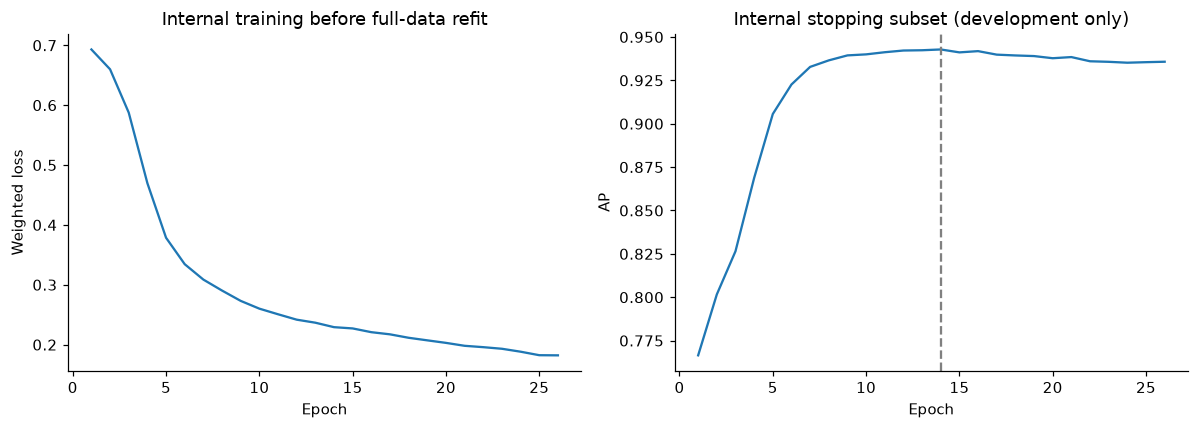

In [9]:
class TorchBinaryClassifier(ClassifierMixin, BaseEstimator):
    def __init__(self, hidden=(64, 32, 16), dropout=0., lr=.001, max_epochs=120,
                 patience=12, seed=SEED, use_log=False, rare=False):
        self.hidden, self.dropout, self.lr = hidden, dropout, lr
        self.max_epochs, self.patience, self.seed = max_epochs, patience, seed
        self.use_log, self.rare = use_log, rare

    def _representation(self):
        return model_pipeline(DummyClassifier(), engineered=False, use_log=self.use_log, rare=self.rare)[:-2]

    def fit(self, X, y):
        start = perf_counter()
        y_array = np.array(y, dtype=int, copy=True)
        train_idx, stop_idx = profile_holdout(X, y_array, n_splits=7)
        stopping_prep = self._representation()
        train_Z = stopping_prep.fit_transform(X.iloc[train_idx], y_array[train_idx]).astype(np.float32)
        stop_Z = stopping_prep.transform(X.iloc[stop_idx]).astype(np.float32)
        seed_network(self.seed)
        net = BinaryNet(train_Z.shape[1], self.hidden, self.dropout)
        optimizer, loss, generator = optimizer_parts(net, y_array[train_idx], self.lr, self.seed)
        tensor = torch.from_numpy(train_Z)
        labels = torch.as_tensor(y_array[train_idx], dtype=torch.long)
        best_AP, best_state, stale = -np.inf, None, 0
        history = []
        for epoch in range(1, self.max_epochs + 1):
            train_loss = training_epoch(net, tensor, labels, optimizer, loss, generator)
            AP = average_precision_score(y_array[stop_idx], tensor_proba(net, stop_Z)[:, 1])
            history.append({'epoch': epoch, 'train_weighted_loss': train_loss, 'stopping_AP': AP})
            if AP > best_AP:
                best_AP, best_state, self.best_epoch_, stale = AP, deepcopy(net.state_dict()), epoch, 0
            else:
                stale += 1
            if stale >= self.patience:
                break
        net.load_state_dict(best_state)
        self.history_ = pd.DataFrame(history)
        self.stopping_epochs_ = epoch
        self.preprocessor_ = self._representation()
        full_Z = self.preprocessor_.fit_transform(X, y_array).astype(np.float32)
        seed_network(self.seed)
        self.net_ = BinaryNet(full_Z.shape[1], self.hidden, self.dropout)
        optimizer, loss, generator = optimizer_parts(self.net_, y_array, self.lr, self.seed)
        tensor, labels = torch.from_numpy(full_Z), torch.as_tensor(y_array, dtype=torch.long)
        self.refit_losses_ = [training_epoch(self.net_, tensor, labels, optimizer, loss, generator)
                              for _ in range(self.best_epoch_)]
        self.classes_ = np.array([0, 1])
        self.n_features_in_ = X.shape[1]
        self.feature_names_in_ = np.asarray(X.columns, dtype=object)
        self.fit_seconds_ = perf_counter() - start
        return self

    def predict_proba(self, X):
        return tensor_proba(self.net_, self.preprocessor_.transform(X).astype(np.float32))

    def predict(self, X):
        return self.classes_[self.predict_proba(X).argmax(axis=1)]


run_search('Deep neural network', TorchBinaryClassifier(use_log=USE_LOG, rare=USE_RARE),
    [{'hidden': [(64, 32, 16), (128, 64, 32)], 'lr': [.001, .0003], 'dropout': [0., .3]}],
    'deep network', representations=False)
oof_rows.append(register_oof('Deep neural network'))
dnn = records['Deep neural network']['model']
display(pd.DataFrame(searches['Deep neural network'].cv_results_)[
    ['param_hidden', 'param_lr', 'param_dropout', 'mean_test_AP', 'std_test_AP', 'mean_fit_time']]
    .sort_values('mean_test_AP', ascending=False).round(4))
display(Markdown(f'**Selected DNN:** hidden={dnn.hidden}, learning rate={dnn.lr}, dropout={dnn.dropout}; '
    f'best internal stopping epoch={dnn.best_epoch_}; {dnn.stopping_epochs_} stopping epochs run, '
    f'then {dnn.best_epoch_} epochs on all {len(X_dev)} development students.'))
dnn.history_.to_csv(RESULTS / 'dnn_stopping_history.csv', index=False)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(dnn.history_.epoch, dnn.history_.train_weighted_loss)
axes[0].set(xlabel='Epoch', ylabel='Weighted loss', title='Internal training before full-data refit')
axes[1].plot(dnn.history_.epoch, dnn.history_.stopping_AP)
axes[1].axvline(dnn.best_epoch_, color='grey', linestyle='--')
axes[1].set(xlabel='Epoch', ylabel='AP', title='Internal stopping subset (development only)')
save_figure(fig, '03_deep_network_learning.png')


## 10. Compare complexity, computation time and classification performance

### Lock decisions and evaluate the common held-out test set

The full-population recommendation is locked by development CV AP; recall at the declared capacity
breaks exact AP ties. Default data availability, target, representation searches, neural budgets,
OOF F2 thresholds and capacity were fixed earlier. Models are not switched after test evaluation.
The transfer arms have a different target-course population and receive a separate table.

Before test evaluation, fit a predeclared sigmoid-calibrated version of the selected workflow using
five development folds and the complete cloned estimator in each fold. It is an additional workflow,
not a replacement chosen after seeing test performance. Its cost includes fold fits; calibrated
probabilities need validation and are not automatically deployment-ready risks.

Search time includes candidates, fold fitting, validation scoring and final refit. Refit time includes
preprocessing; DNN refit includes stopping selection plus full-development training. Median batch
prediction time over three repeats includes preprocessing and is reported per student. Different
candidate counts and optimizer budgets prevent universal algorithm-speed claims.


In [10]:
dev_table = development_table()
CHOSEN = dev_table.drop(index='Prior baseline').index[0]
locked = {'selected_model': CHOSEN, 'selection_metric': 'mean development CV AP',
    'capacity': CAPACITY, 'seed': SEED, 'log': USE_LOG, 'rare_pooling': USE_RARE,
    'target_course': int(target_course), 'excluded_fields': EXCLUDED,
    'models': {name: {'parameters': describe_parameters(item['parameters']), 'threshold': item['threshold'],
                      'CV_AP': item['CV_AP']} for name, item in records.items()}}
(RESULTS / 'locked_choices.json').write_text(json.dumps(locked, indent=2), encoding='utf-8')
print('Locked recommendation before test evaluation:', CHOSEN)
start = perf_counter()
calibrated = CalibratedClassifierCV(estimator=clone(records[CHOSEN]['model']), method='sigmoid',
    cv=FOLDS, ensemble=True, n_jobs=1)
calibrated.fit(X_dev, y_dev)
calibration_seconds = perf_counter() - start
print(f'Additional development-only calibration fit: {calibration_seconds:.2f}s')


def complexity(model):
    if isinstance(model, TorchBinaryClassifier):
        return f'{sum(p.numel() for p in model.net_.parameters()):,} parameters; {model.best_epoch_} full-data epochs'
    estimator = model.named_steps['model']
    if isinstance(estimator, KNeighborsClassifier):
        return f'{estimator.n_samples_fit_:,} stored rows; k={estimator.n_neighbors}'
    if isinstance(estimator, DecisionTreeClassifier):
        return f'{estimator.tree_.node_count} nodes; depth {estimator.get_depth()}'
    if isinstance(estimator, SVC):
        return f'{len(estimator.support_):,} support vectors; {estimator.kernel} kernel'
    if isinstance(estimator, (AdaBoostClassifier, BaggingClassifier)):
        members = estimator.estimators_
        if isinstance(members[0], DecisionTreeClassifier):
            return f'{len(members)} trees; {sum(m.tree_.node_count for m in members):,} nodes'
        return f'{len(members)} KNN members; {sum(m.n_samples_fit_ for m in members):,} stored row instances'
    return 'Constant class priors'


test_scores, test_predictions, test_rows = {}, {}, []
for name, item in records.items():
    model = item['model']
    score = risk_scores(model, X_test)
    predicted = score >= item['threshold']
    timings = []
    for _ in range(3):
        start = perf_counter()
        repeated = risk_scores(model, X_test)
        timings.append(perf_counter() - start)
        assert np.allclose(score, repeated)
    test_scores[name], test_predictions[name] = score, predicted
    test_rows.append({'model': name, 'AP': average_precision_score(y_test, score),
        'ROC_AUC': roc_auc_score(y_test, score), 'accuracy': accuracy_score(y_test, predicted),
        'balanced_accuracy': balanced_accuracy_score(y_test, predicted),
        'precision': precision_score(y_test, predicted, zero_division=0),
        'recall': recall_score(y_test, predicted), 'F1': f1_score(y_test, predicted),
        'F2': fbeta_score(y_test, predicted, beta=2), **capacity_metrics(y_test, score),
        'search_seconds': item['search_seconds'], 'refit_seconds': item['refit_seconds'],
        'score_ms_per_student': 1000*np.median(timings)/len(X_test), 'complexity': complexity(model)})
test_results = pd.DataFrame(test_rows).set_index('model')
display(test_results.drop(columns='complexity').round(4))
display(test_results[['complexity']])
test_results.to_csv(RESULTS / 'test_metrics.csv')
dev_table.to_csv(RESULTS / 'development_models.csv')
pd.DataFrame(oof_rows).to_csv(RESULTS / 'development_oof_rules.csv', index=False)
predictions = pd.DataFrame({'row_id': X_test.index, 'dropout_label': y_test.to_numpy()})
for name in records:
    predictions[f'{name}_score'] = test_scores[name]
    predictions[f'{name}_alert'] = test_predictions[name]
predictions.to_csv(RESULTS / 'test_predictions.csv', index=False)


Locked recommendation before test evaluation: AdaBoost trees


Additional development-only calibration fit: 2.67s


,AP,ROC_AUC,accuracy,balanced_accuracy,precision,recall,F1,F2,contacts,dropouts_reached,other_contacts,precision_at_capacity,recall_at_capacity,search_seconds,refit_seconds,score_ms_per_student
model,,,,,,,,,,,,,,,,
Prior baseline,0.3912,0.5000,0.3912,0.5000,0.3912,1.0000,0.5624,0.7626,146,46,100,0.3151,0.1620,0.2777,0.0264,0.0138
KNN,0.9324,0.9384,0.8485,0.8554,0.7636,0.8873,0.8208,0.8595,146,146,0,1.0000,0.5141,10.2368,0.0214,0.0348
Decision tree,0.9190,0.9241,0.7865,0.8108,0.6633,0.9225,0.7717,0.8556,146,144,2,0.9863,0.5070,9.4583,0.0294,0.0117
SVM,0.9431,0.9467,0.8609,0.8669,0.7815,0.8944,0.8342,0.8693,146,146,0,1.0000,0.5141,41.8102,0.1680,0.1011
AdaBoost trees,0.9466,0.9476,0.8691,0.8755,0.7908,0.9049,0.8440,0.8795,146,146,0,1.0000,0.5141,19.4086,0.7234,0.0445
Bagged KNN,0.9305,0.9341,0.8251,0.8375,0.7236,0.8944,0.8000,0.8541,146,146,0,1.0000,0.5141,23.8459,0.1782,0.4173
Tree bagging control,0.9002,0.9256,0.7603,0.7944,0.6279,0.9507,0.7563,0.8621,146,141,5,0.9658,0.4965,0.8446,0.0437,0.0087
Bagged trees,0.9451,0.9480,0.8760,0.8768,0.8170,0.8803,0.8475,0.8669,146,146,0,1.0000,0.5141,15.2711,0.7717,0.0194
Deep neural network,0.9432,0.9465,0.8402,0.8543,0.7373,0.9190,0.8182,0.8758,146,146,0,1.0000,0.5141,62.9657,1.1118,0.0060


,complexity
model,
Prior baseline,Constant class priors
KNN,"2,904 stored rows; k=31"
Decision tree,85 nodes; depth 8
SVM,897 support vectors; rbf kernel
AdaBoost trees,80 trees; 502 nodes
Bagged KNN,"30 KNN members; 87,120 stored row instances"
Tree bagging control,57 nodes; depth 5
Bagged trees,"60 trees; 3,100 nodes"
Deep neural network,"23,714 parameters; 14 full-data epochs"


### Curves, uncertainty and advisor workload

Confusion matrices use the frozen F2 alert rule. Capacity evaluation separately ranks scores and
contacts a fixed number of students. Test-row bootstrap intervals are conditional on the fitted
models and the observed class counts; they exclude retraining, tuning and cohort-change uncertainty.
Capacity metrics are reranked in each stratified bootstrap sample. Training permutation importance
describes dependence of the full fitted pipeline on raw inputs, not causes or intervention effects;
engineered features are recomputed after permutation. It is not used to revise model selection.


,precision,recall,f1-score,support
Graduate,0.933,0.846,0.887,442.000
Dropout,0.791,0.905,0.844,284.000
accuracy,0.869,0.869,0.869,0.869
macro avg,0.862,0.876,0.866,726.000
weighted avg,0.877,0.869,0.870,726.000


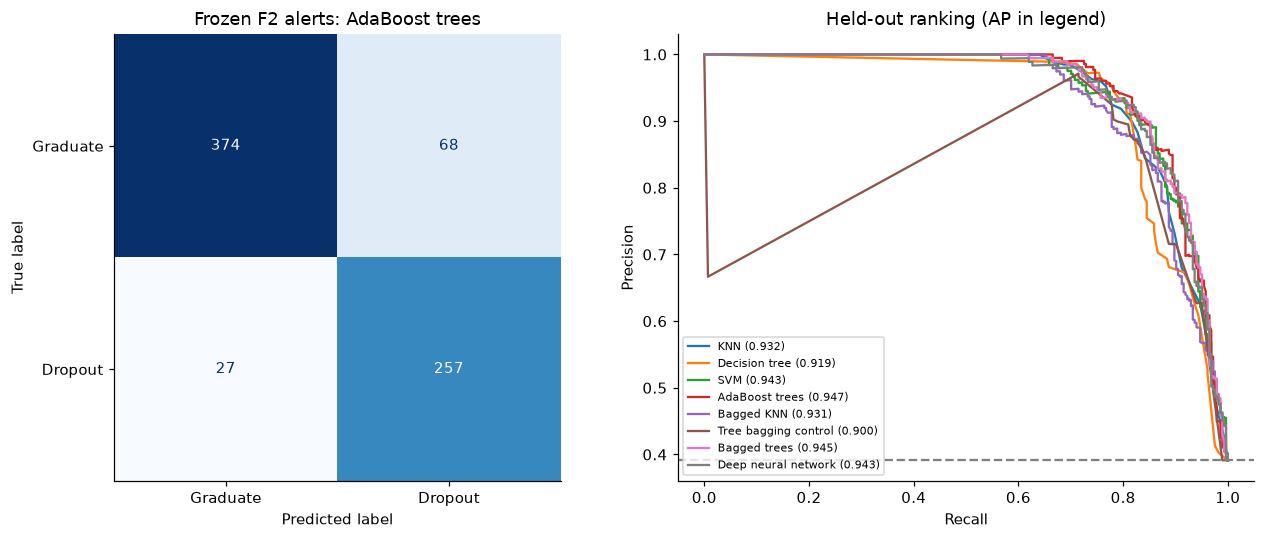

,capacity,contacts,dropouts_reached,other_contacts,precision_at_capacity,recall_at_capacity
0,0.05,37,37,0,1.0000,0.1303
1,0.10,73,73,0,1.0000,0.2570
2,0.20,146,146,0,1.0000,0.5141
3,0.30,218,212,6,0.9725,0.7465
4,0.50,363,261,102,0.7190,0.9190


,lower_95pct,upper_95pct
AP,0.9306,0.9619
precision_at_capacity,1.0000,1.0000
recall_at_capacity,0.5141,0.5141


,raw_feature,training_AP_decrease,repeat_SD
26,Curricular units 2nd sem (approved),0.3447,0.0097
20,Curricular units 1st sem (approved),0.0919,0.0034
24,Curricular units 2nd sem (enrolled),0.0341,0.0007
18,Curricular units 1st sem (enrolled),0.0185,0.0011
27,Curricular units 2nd sem (grade),0.0065,0.0008
15,Age at enrollment,0.0047,0.0005
14,Scholarship holder,0.0046,0.0013
3,Course,0.0039,0.0003
2,Application order,0.0004,0.0000
10,Father's occupation,0.0004,0.0000


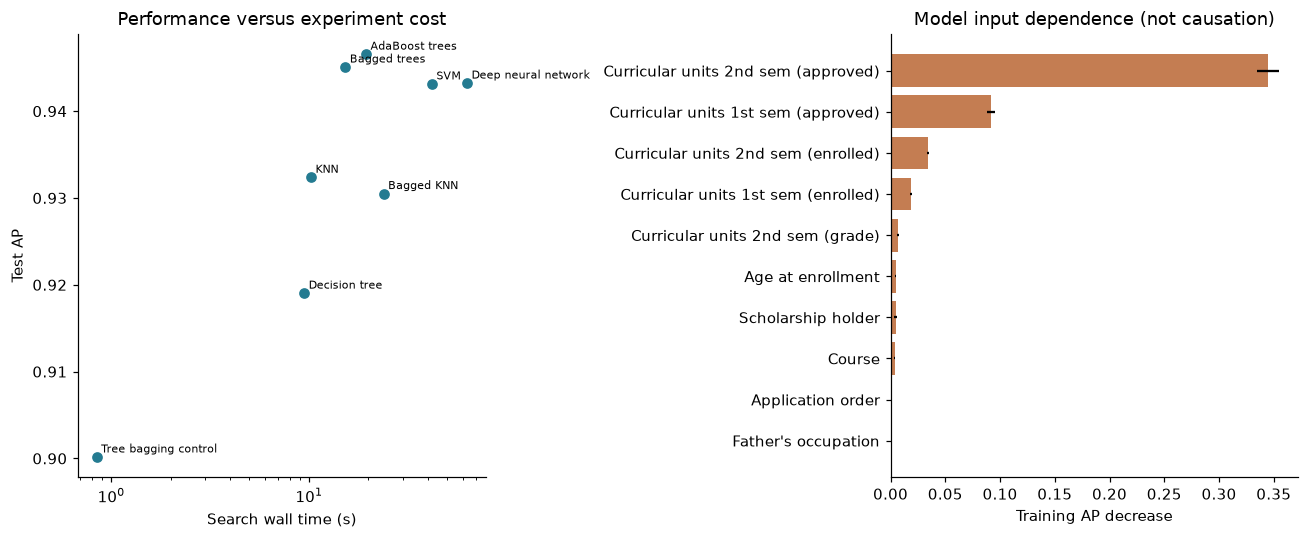

In [11]:
truth = y_test.to_numpy()
selected = test_results.loc[CHOSEN]
score = test_scores[CHOSEN]
display(pd.DataFrame(classification_report(y_test, test_predictions[CHOSEN],
    labels=[0, 1], target_names=['Graduate', 'Dropout'], output_dict=True, zero_division=0)).T.round(3))
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
ConfusionMatrixDisplay.from_predictions(y_test, test_predictions[CHOSEN], labels=[0, 1],
    display_labels=['Graduate', 'Dropout'], colorbar=False, cmap='Blues', ax=axes[0])
axes[0].set_title(f'Frozen F2 alerts: {CHOSEN}')
for name in records:
    if name != 'Prior baseline':
        p, r, _ = precision_recall_curve(y_test, test_scores[name])
        axes[1].plot(r, p, label=f'{name} ({test_results.loc[name, "AP"]:.3f})')
axes[1].axhline(y_test.mean(), linestyle='--', color='grey')
axes[1].set(xlabel='Recall', ylabel='Precision', title='Held-out ranking (AP in legend)')
axes[1].legend(fontsize=7)
save_figure(fig, '04_test_classification.png')

capacity_rows = [{'capacity': c, **capacity_metrics(y_test, score, c)} for c in [.05, .1, .2, .3, .5]]
capacity_table = pd.DataFrame(capacity_rows)
display(capacity_table.round(4))
capacity_table.to_csv(RESULTS / 'capacity_sensitivity.csv', index=False)
rng = np.random.default_rng(SEED)
groups = [np.flatnonzero(truth == label) for label in [0, 1]]
bootstrap = []
for _ in range(1000):
    indices = np.concatenate([rng.choice(group, len(group), replace=True) for group in groups])
    rng.shuffle(indices)
    bootstrap.append({'AP': average_precision_score(truth[indices], score[indices]),
                      **capacity_metrics(truth[indices], score[indices])})
intervals = pd.DataFrame(bootstrap)[['AP', 'precision_at_capacity', 'recall_at_capacity']].quantile([.025, .975]).T
intervals.columns = ['lower_95pct', 'upper_95pct']
display(intervals.round(4))
intervals.to_csv(RESULTS / 'conditional_test_intervals.csv')

importance = permutation_importance(records[CHOSEN]['model'], X_dev, y_dev,
    scoring='average_precision', n_repeats=3, random_state=SEED, n_jobs=1)
importance_table = pd.DataFrame({'raw_feature': X_dev.columns, 'training_AP_decrease': importance.importances_mean,
    'repeat_SD': importance.importances_std}).sort_values('training_AP_decrease', ascending=False)
display(importance_table.head(10).round(4))
importance_table.to_csv(RESULTS / 'training_permutation_importance.csv', index=False)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
plot = test_results.drop(index='Prior baseline')
axes[0].scatter(plot.search_seconds, plot.AP, color='#247b91')
for name, row in plot.iterrows():
    axes[0].annotate(name, (row.search_seconds, row.AP), fontsize=7, xytext=(3, 3), textcoords='offset points')
axes[0].set(xscale='log', xlabel='Search wall time (s)', ylabel='Test AP', title='Performance versus experiment cost')
top = importance_table.head(10).iloc[::-1]
axes[1].barh(top.raw_feature, top.training_AP_decrease, xerr=top.repeat_SD, color='#c47d52')
axes[1].set(xlabel='Training AP decrease', title='Model input dependence (not causation)')
save_figure(fig, '05_cost_and_input_dependence.png')


### Transfer on identical target-course students; probability reliability

Target scratch and source-pretrained models are evaluated on exactly the same target-course test
rows. The additional global-model rows below also use this subset, allowing a practical comparison;
their access to source/target labels and optimization differ. Only the matched transfer arms isolate
initialization. A paired stratified bootstrap interval describes their AP difference, conditional on
the fitted networks. Failure to find a gain is a result, not a reason to tune on target test labels.

Brier score and log-loss assess probabilities, whereas AP assesses ranking. Raw SVM margins are
excluded from probability metrics. The separately predeclared calibration workflow does not replace
the locked model based on test outcomes.


Target test students: 133 ; dropouts: 20


,target_AP,contacts,dropouts_reached,other_contacts,precision_at_capacity,recall_at_capacity,source_seconds,target_fit_seconds,score_ms_per_student
model,,,,,,,,,
Target scratch,0.8662,27,16,11,0.5926,0.80,0.0000,0.8809,0.0299
Source pretrained,0.8690,27,17,10,0.6296,0.85,4.7761,1.0558,0.0300
Prior baseline,0.1504,27,3,24,0.1111,0.15,NaN,NaN,NaN
KNN,0.8823,27,17,10,0.6296,0.85,NaN,NaN,NaN
Decision tree,0.8928,27,17,10,0.6296,0.85,NaN,NaN,NaN
SVM,0.8995,27,18,9,0.6667,0.90,NaN,NaN,NaN
AdaBoost trees,0.8819,27,17,10,0.6296,0.85,NaN,NaN,NaN
Bagged KNN,0.8946,27,17,10,0.6296,0.85,NaN,NaN,NaN
Tree bagging control,0.8425,27,17,10,0.6296,0.85,NaN,NaN,NaN


**Matched transfer:** AP difference **+0.0027**, conditional paired 95% interval **[-0.0528, +0.0582]**. This does not include variability from new training seeds or a different target course.

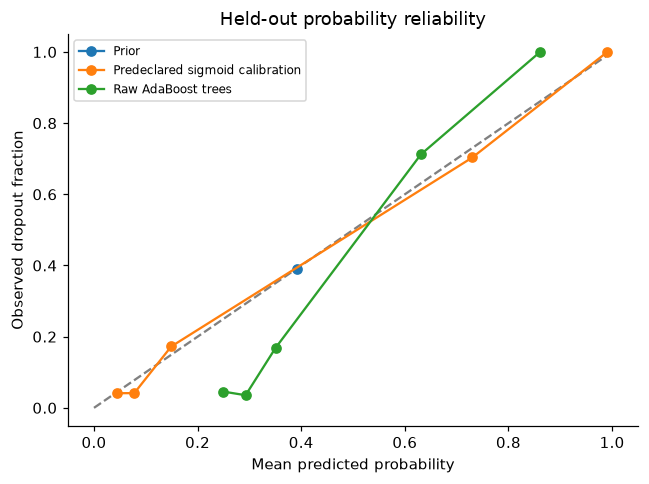

,Brier,log_loss,AP
workflow,,,
Prior,0.2382,0.6693,0.3912
Predeclared sigmoid calibration,0.0761,0.2573,0.9444
Raw AdaBoost trees,0.1092,0.3826,0.9466


In [12]:
target_test_X = X_test.loc[X_test.Course == target_course]
target_test_y = y_test.loc[target_test_X.index]
assert set(target_test_y) == {0, 1}
target_test_Z = transfer_prep.transform(target_test_X).astype(np.float32)
transfer_test_scores, transfer_rows = {}, []
for name, item in transfer_arms.items():
    scores = tensor_proba(item['model'], target_test_Z)[:, 1]
    transfer_test_scores[name] = scores
    start = perf_counter()
    for _ in range(3):
        tensor_proba(item['model'], transfer_prep.transform(target_test_X).astype(np.float32))
    per_student_ms = 1000*(perf_counter()-start)/(3*len(target_test_X))
    transfer_rows.append({'model': name, 'target_AP': average_precision_score(target_test_y, scores),
        **capacity_metrics(target_test_y, scores), 'source_seconds': item['source_seconds'],
        'target_fit_seconds': item['target_fit_seconds'], 'score_ms_per_student': per_student_ms})
target_mask = (X_test.Course == target_course).to_numpy()
for name in records:
    transfer_rows.append({'model': name, 'target_AP': average_precision_score(target_test_y, test_scores[name][target_mask]),
        **capacity_metrics(target_test_y, test_scores[name][target_mask])})
transfer_results = pd.DataFrame(transfer_rows).set_index('model')
print('Target test students:', len(target_test_y), '; dropouts:', int(target_test_y.sum()))
display(transfer_results.round(4))
transfer_results.to_csv(RESULTS / 'target_course_test.csv')
transfer_truth = target_test_y.to_numpy()
target_groups = [np.flatnonzero(transfer_truth == value) for value in [0, 1]]
rng = np.random.default_rng(SEED)
transfer_differences = []
for _ in range(1000):
    indices = np.concatenate([rng.choice(g, len(g), replace=True) for g in target_groups])
    transfer_differences.append(average_precision_score(transfer_truth[indices], transfer_test_scores['Source pretrained'][indices])
        - average_precision_score(transfer_truth[indices], transfer_test_scores['Target scratch'][indices]))
transfer_delta = transfer_results.loc['Source pretrained', 'target_AP'] - transfer_results.loc['Target scratch', 'target_AP']
transfer_interval = np.quantile(transfer_differences, [.025, .975])
display(Markdown(f'**Matched transfer:** AP difference **{transfer_delta:+.4f}**, conditional paired '
    f'95% interval **[{transfer_interval[0]:+.4f}, {transfer_interval[1]:+.4f}]**. '
    'This does not include variability from new training seeds or a different target course.'))

probability_variants = {'Prior': np.full(len(y_test), y_dev.mean()),
    'Predeclared sigmoid calibration': calibrated.predict_proba(X_test)[:, 1]}
if hasattr(records[CHOSEN]['model'], 'predict_proba'):
    probability_variants[f'Raw {CHOSEN}'] = test_scores[CHOSEN]
probability_rows = []
fig, ax = plt.subplots(figsize=(6, 4.5))
ax.plot([0, 1], [0, 1], '--', color='grey')
for name, p in probability_variants.items():
    assert np.isfinite(p).all() and ((p >= 0) & (p <= 1)).all()
    observed, predicted = calibration_curve(y_test, p, n_bins=5, strategy='quantile')
    ax.plot(predicted, observed, marker='o', label=name)
    probability_rows.append({'workflow': name, 'Brier': brier_score_loss(y_test, p),
        'log_loss': log_loss(y_test, p), 'AP': average_precision_score(y_test, p)})
ax.set(xlabel='Mean predicted probability', ylabel='Observed dropout fraction', title='Held-out probability reliability')
ax.legend(fontsize=8)
save_figure(fig, '06_probability_reliability.png')
probability_results = pd.DataFrame(probability_rows).set_index('workflow')
display(probability_results.round(4))
probability_results.to_csv(RESULTS / 'probability_reliability.csv')


### Subgroups, unresolved students and results-based discussion

Gender codes remain anonymous. Apply the same global alert threshold and contact list to each group;
do not set group-specific thresholds after inspecting test results. These limited diagnostics do not
establish fairness. Scores for unresolved students have no verified eventual labels, so no accuracy,
precision or recall is calculated for them. They do not establish eligibility at the decision date.


In [13]:
contact = np.zeros(len(y_test), dtype=bool)
contact[np.argsort(-score, kind='stable')[:int(np.ceil(CAPACITY*len(y_test)))]] = True
subgroups = []
for value in sorted(X_test.Gender.unique()):
    mask = (X_test.Gender == value).to_numpy()
    labels = truth[mask]
    subgroups.append({'gender_code': value, 'students': int(mask.sum()), 'dropouts': int(labels.sum()),
        'alert_precision': precision_score(labels, test_predictions[CHOSEN][mask], zero_division=0),
        'alert_recall': recall_score(labels, test_predictions[CHOSEN][mask], zero_division=0),
        'contact_rate': contact[mask].mean(),
        'dropout_recall_in_global_contacts': labels[contact[mask]].sum()/labels.sum() if labels.sum() else np.nan})
display(pd.DataFrame(subgroups).round(4))
pd.DataFrame(subgroups).to_csv(RESULTS / 'limited_subgroup_diagnostic.csv', index=False)
unresolved_X = unresolved.drop(columns=['Target'] + EXCLUDED)
unresolved_scores = risk_scores(records[CHOSEN]['model'], unresolved_X)
pd.DataFrame({'row_id': unresolved.index, 'recorded_status': 'Enrolled', 'model_score': unresolved_scores,
              'eventual_outcome_verified': False}).to_csv(RESULTS / 'unresolved_scores_unvalidated.csv', index=False)
print(f'Exported {len(unresolved_scores)} unvalidated scores for unresolved students; no outcome metric is calculated.')

test_leader = test_results.drop(index='Prior baseline').AP.idxmax()
fastest = test_results.drop(index='Prior baseline').refit_seconds.idxmin()
tn, fp, fn, tp = confusion_matrix(y_test, test_predictions[CHOSEN], labels=[0, 1]).ravel()
expected_random = selected.contacts * y_test.mean()
best_capacity_value = test_results.drop(index='Prior baseline').recall_at_capacity.max()
capacity_leaders = test_results.drop(index='Prior baseline').index[
    np.isclose(test_results.drop(index='Prior baseline').recall_at_capacity, best_capacity_value)].tolist()
discussion = f"""
**Answer for the resolved-outcome population.** Development CV selected **{CHOSEN}**.
On **{len(y_test)}** held-out students, including **{int(y_test.sum())}** recorded dropouts, it obtains
AP **{selected.AP:.3f}** (conditional bootstrap interval **{intervals.loc['AP', 'lower_95pct']:.3f}–{intervals.loc['AP', 'upper_95pct']:.3f}**)
and ROC-AUC **{selected.ROC_AUC:.3f}**. The descriptive test AP leader is {test_leader}; the recommendation
remains the one chosen before seeing test labels. Small differences do not establish universal superiority.

**Advisor workload.** At {CAPACITY:.0%} capacity, the ranking contacts **{int(selected.contacts)}** students,
including **{int(selected.dropouts_reached)}** recorded dropouts and **{int(selected.other_contacts)}** graduates.
Precision is **{selected.precision_at_capacity:.1%}**, recall **{selected.recall_at_capacity:.1%}**; random
selection would reach about **{expected_random:.1f}** dropout cases at this prevalence. The maximum observed
test recall at that budget is shared by {', '.join(capacity_leaders)}. AP selection and a single contact
budget need not identify the same leader. The capacity table illustrates workload trade-offs, not test tuning.

**Separate F2 alert rule.** The locked threshold finds {tp} dropout cases, misses {fn}, and flags {fp}
graduates; {tn} graduates are correctly unflagged. This rule can exceed the appointment budget.
Neither the contact counts nor the alert counts measure preventable dropout or benefits from intervention.

**Resources and explanation.** The selected workflow uses {selected.complexity}. Its search costs
{selected.search_seconds:.2f} s, selected refit {selected.refit_seconds:.3f} s and batch prediction
{selected.score_ms_per_student:.4f} ms per student on this CPU. The fastest non-dummy refit is {fastest}.
Differences in trial counts and training protocols matter. Training permutation dependence is largest for
`{importance_table.iloc[0].raw_feature}`; correlated inputs can share importance, and dependence is not causation.
"""
display(Markdown(discussion))
summary = {'selected_model': CHOSEN, 'test_AP': float(selected.AP),
    'AP_interval': intervals.loc['AP'].tolist(), 'contacts': int(selected.contacts),
    'dropouts_reached': int(selected.dropouts_reached), 'precision_at_capacity': float(selected.precision_at_capacity),
    'recall_at_capacity': float(selected.recall_at_capacity), 'transfer_AP_difference': float(transfer_delta),
    'transfer_interval': transfer_interval.tolist(), 'target_test_students': len(target_test_y),
    'calibration_fit_seconds': calibration_seconds}
(RESULTS / 'summary.json').write_text(json.dumps(summary, indent=2), encoding='utf-8');


,gender_code,students,dropouts,alert_precision,alert_recall,contact_rate,dropout_recall_in_global_contacts
0,0,455,126,0.7219,0.8651,0.1341,0.4841
1,1,271,158,0.8506,0.9367,0.3137,0.5380


Exported 794 unvalidated scores for unresolved students; no outcome metric is calculated.



**Answer for the resolved-outcome population.** Development CV selected **AdaBoost trees**.
On **726** held-out students, including **284** recorded dropouts, it obtains
AP **0.947** (conditional bootstrap interval **0.931–0.962**)
and ROC-AUC **0.948**. The descriptive test AP leader is AdaBoost trees; the recommendation
remains the one chosen before seeing test labels. Small differences do not establish universal superiority.

**Advisor workload.** At 20% capacity, the ranking contacts **146** students,
including **146** recorded dropouts and **0** graduates.
Precision is **100.0%**, recall **51.4%**; random
selection would reach about **57.1** dropout cases at this prevalence. The maximum observed
test recall at that budget is shared by KNN, SVM, AdaBoost trees, Bagged KNN, Bagged trees, Deep neural network. AP selection and a single contact
budget need not identify the same leader. The capacity table illustrates workload trade-offs, not test tuning.

**Separate F2 alert rule.** The locked threshold finds 257 dropout cases, misses 27, and flags 68
graduates; 374 graduates are correctly unflagged. This rule can exceed the appointment budget.
Neither the contact counts nor the alert counts measure preventable dropout or benefits from intervention.

**Resources and explanation.** The selected workflow uses 80 trees; 502 nodes. Its search costs
19.41 s, selected refit 0.723 s and batch prediction
0.0445 ms per student on this CPU. The fastest non-dummy refit is KNN.
Differences in trial counts and training protocols matter. Training permutation dependence is largest for
`Curricular units 2nd sem (approved)`; correlated inputs can share importance, and dependence is not causation.


### Complexity, limitations and what would be required for real use

KNN stores about O(n d) values and brute-force scoring compares a student with those training rows.
A tree predicts along a path of depth h; bagging B trees costs roughly B path traversals, while
bagged KNN repeats neighbour searches. AdaBoost sums its shallow-tree contributions. Kernel SVM
prediction depends on the number of support vectors and their dimension; linear scoring can in
principle be represented more compactly than the general SVC implementation. A dense DNN's forward
work is proportional to its weights, with additional repeated work during training. Representation
cost matters too: PCA/LDA projection and encoding are included in the measured scoring times.

The model-size counts are not interchangeable measures of memory or explainability. A reduced
representation can help computation while harming discrimination; retaining original columns can
support advisor explanation. Model preference should reflect measured ranking, usable explanations,
resource requirements and their uncertainty, not the sophistication of the algorithm name.

The experiment excludes unresolved outcomes and cannot establish performance across all active
students. Random splits do not validate later cohorts or other institutions. Missing dropout dates,
unverified administrative measurement times, shared cohort-level economic variables, single-seed
neural training, repeated development selection, limited grids and conditional uncertainty intervals
all limit inference. Transfer compares one course only and does not add external-institution evidence.
Calibration diagnostics on one test sample do not establish reliable probabilities in deployment.
The subgroup table is descriptive, not a fairness guarantee. Actual adoption would require timestamped
eligible cohorts, prospective/group-specific evaluation and a study of support effectiveness.

### References

- Local brief: `../../IT3212-2026-Assignment 3.pdf`, points 1–10. It specifies 200 total points and
  130 to pass, but no submission format or word limit; those are not inherited from Assignment 1.
- [Realinho et al. (2022), Predicting Student Dropout and Academic Success](https://doi.org/10.3390/data7110146).
- [UCI dataset](https://archive.ics.uci.edu/dataset/697/predict+students+dropout+and+academic+success).
- scikit-learn: [leakage and pipelines](https://scikit-learn.org/stable/common_pitfalls.html),
  [feature selection](https://scikit-learn.org/stable/modules/feature_selection.html),
  [PCA](https://scikit-learn.org/stable/modules/decomposition.html#pca),
  [LDA](https://scikit-learn.org/stable/modules/generated/sklearn.discriminant_analysis.LinearDiscriminantAnalysis.html),
  [ensembles](https://scikit-learn.org/stable/modules/ensemble.html),
  [calibration](https://scikit-learn.org/stable/modules/calibration.html).
- [PyTorch neural-network modules](https://docs.pytorch.org/docs/stable/nn.html).
- Reviewed Git versions are identified in the opening contribution table; no saved scores were copied
  from their notebooks. All reported numbers in this notebook come from its own execution.
